<a href="https://colab.research.google.com/github/Chile49/Ch25/blob/main/COU07506_Week02_240242458495.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2 — Lab 1A: Sampling, Aliasing and Quantization
* **Name:** VICTOR NKUMINGI DAVID
* **Registration Number:** 240242458495
* **Date:** 25/11/2026

## Pre-lab Preparation
* **(a) Alias frequency:** With \( f_s = 10\text{ kHz} \), the folding frequency is \( f_s / 2 = 5\text{ kHz} \). Since \( 7\text{ kHz} > 5\text{ kHz} \), aliasing occurs and the signal appears at \( F_{\text{alias}} = |7 - 1 \times 10| = 3\text{ kHz} \).
* **(b) Step size and theoretical SQNR:** For \( B = 8\text{ bits} \) and \( X_m = 1\text{ V} \):
  * Step size: \( \Delta = \frac{2X_m}{2^B} = \frac{2(1)}{2^8} = \frac{2}{256} \approx 0.0078125\text{ V} \) (\( 7.81\text{ mV} \))
  * Theoretical SQNR: \( \text{SQNR} \approx 6.02(8) + 1.76 = 49.92\text{ dB} \)


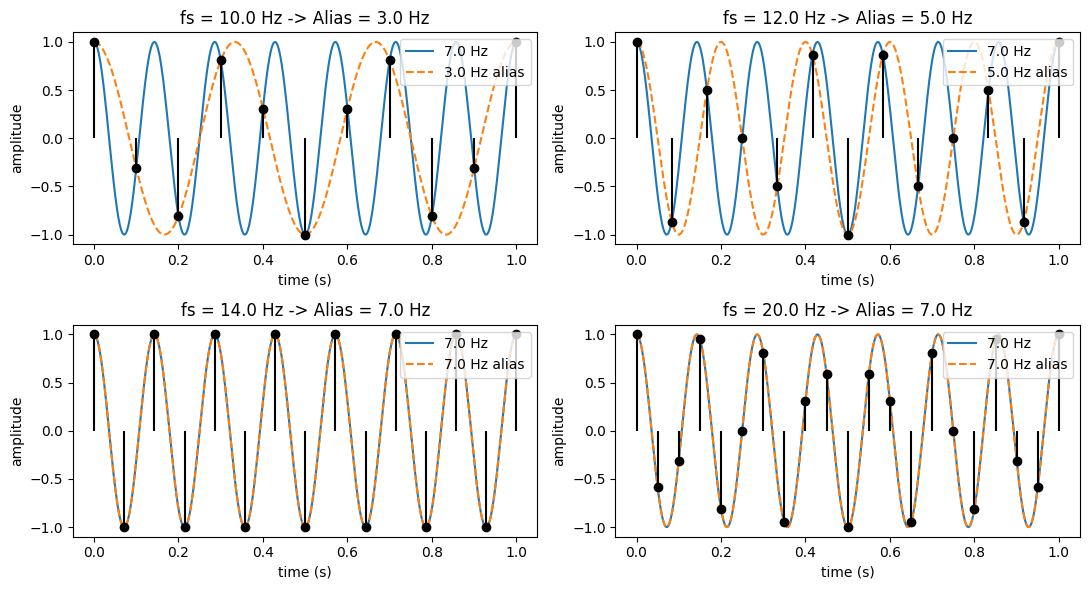

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

f0 = 7.0
t = np.linspace(0, 1, 2000)

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for ax, fs in zip(axes.flat, [10.0, 12.0, 14.0, 20.0]):
    n = np.arange(0, int(fs) + 1)
    tn = n / fs
    f_alias = abs(f0 - fs * round(f0 / fs))
    ax.plot(t, np.cos(2 * np.pi * f0 * t), label=f"{f0} Hz")
    ax.plot(t, np.cos(2 * np.pi * f_alias * t), "--", label=f"{f_alias} Hz alias")
    ax.stem(tn, np.cos(2 * np.pi * f0 * tn), linefmt="k-", markerfmt="ko", basefmt=" ")
    ax.set_title(f"fs = {fs} Hz -> Alias = {f_alias} Hz")
    ax.set_xlabel("time (s)")
    ax.set_ylabel("amplitude")
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()


### Task 2.1 — Alias Frequency Table (\( F = 7\text{ Hz} \))

| Sampling Rate \( f_s \) (Hz) | Folding Frequency \( f_s / 2 \) (Hz) | Integer \( k \) | Measured Alias (Hz) | Formula \( |F - k f_s| \) (Hz) |
| :--- | :--- | :--- | :--- | :--- |
| 10 | 5 | 1 | 3.0 | \( |7 - 1(10)| = 3.0 \) |
| 12 | 6 | 1 | 5.0 | \( |7 - 1(12)| = 5.0 \) |
| 14 | 7 | 0 or 1 | 7.0 | \( |7 - 0(14)| = 7.0 \) |
| 20 | 10 | 0 | 7.0 | \( |7 - 0(20)| = 7.0 \) |


In [9]:
import os
from IPython.display import Audio, display

fname = "my_voice.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
    x = x / np.max(np.abs(x))
else:
    fs = 44100
    t = np.arange(0, 3, 1 / fs)
    x = 0.5 * signal.chirp(t, 200, 3, 15000)

for k in [2, 4, 8, 16]:
    naive = x[::k]
    proper = signal.decimate(x, k, ftype="fir")
    print(f"k = {k}, new fs = {fs // k} Hz")
    if k == 8:
        print("Naive k=8 (aliased):")
        display(Audio(naive, rate=fs // k))
        print("Decimated k=8 (filtered):")
        display(Audio(proper, rate=fs // k))

k = 2, new fs = 22050 Hz
k = 4, new fs = 11025 Hz
k = 8, new fs = 5512 Hz
Naive k=8 (aliased):


Decimated k=8 (filtered):


k = 16, new fs = 2756 Hz


### Task 2.2 — Listening Observations (\( k = 8 \))
* **Naïve down-sampling (`x[::8]`):** Without an anti-aliasing filter, high-frequency components fold back into the lower frequency band, creating harsh metallic distortion, robotic artifacts, or downward-sweeping ghost tones.
* **Filtered decimation (`signal.decimate`):** Because the low-pass filter removes frequencies above the new Nyquist limit before dropping samples, the audio sounds muffled (lacking sharp treble) but completely clean and free of unnatural distortion.


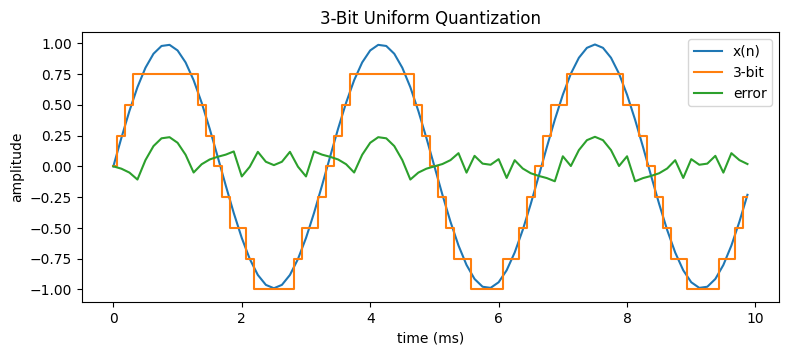

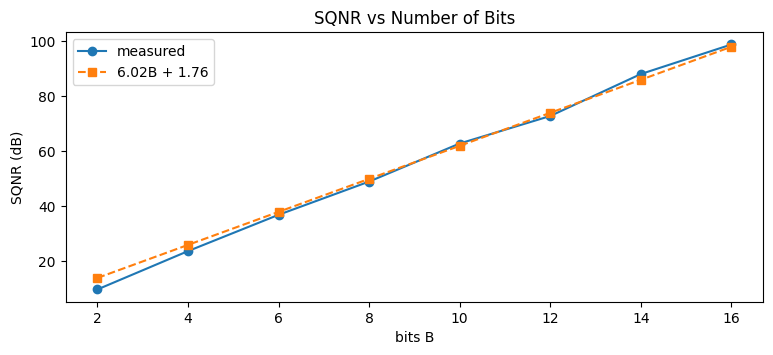

Speech/Audio 4-bit SQNR = 20.36 dB


Speech/Audio 8-bit SQNR = 44.05 dB


Speech/Audio 12-bit SQNR = 68.01 dB


Speech/Audio 16-bit SQNR = 92.08 dB


In [10]:
def quantize(x, bits, full_scale=1.0):
    delta = 2 * full_scale / 2**bits
    q = np.round(x / delta) * delta
    return np.clip(q, -full_scale, full_scale - delta)

fs_sine = 8000
t_sine = np.arange(0, 0.01, 1 / fs_sine)
x_sine = 0.99 * np.sin(2 * np.pi * 300 * t_sine)
xq = quantize(x_sine, 3)

plt.figure(figsize=(9, 3.5))
plt.plot(t_sine * 1e3, x_sine, label="x(n)")
plt.step(t_sine * 1e3, xq, where="mid", label="3-bit")
plt.plot(t_sine * 1e3, x_sine - xq, label="error")
plt.title("3-Bit Uniform Quantization")
plt.xlabel("time (ms)")
plt.ylabel("amplitude")
plt.legend()
plt.show()

bits = np.arange(2, 17, 2)
meas = [10 * np.log10(np.sum(x_sine**2) / np.sum((x_sine - quantize(x_sine, B))**2)) for B in bits]

plt.figure(figsize=(9, 3.5))
plt.plot(bits, meas, "o-", label="measured")
plt.plot(bits, 6.02 * bits + 1.76, "s--", label="6.02B + 1.76")
plt.title("SQNR vs Number of Bits")
plt.xlabel("bits B")
plt.ylabel("SQNR (dB)")
plt.legend()
plt.show()

for B in [4, 8, 12, 16]:
    xq_voice = quantize(x, B)
    err_voice = x - xq_voice
    sqnr_voice = 10 * np.log10(np.sum(x**2) / np.sum(err_voice**2))
    print(f"Speech/Audio {B}-bit SQNR = {sqnr_voice:.2f} dB")
    display(Audio(xq_voice, rate=fs))

### Task 2.5 — Why Speech SQNR Is Lower Than a Full-Scale Sine Wave
The theoretical formula \( \text{SQNR} \approx 6.02B + 1.76\text{ dB} \) assumes a continuous full-scale sinusoid whose average power is \( X_m^2 / 2 \). Real speech has pauses, quiet syllables, and sharp peaks, giving it a much lower average signal power for the same quantization noise floor, which lowers the measured SQNR.

## Analysis Questions
1. **Why 7 Hz appears at 3 Hz when \( f_s = 10\text{ Hz} \):** At \( f_s = 10\text{ Hz} \), unique frequencies only exist from \( 0 \) to \( 5\text{ Hz} \) (\( f_s/2 \)). Sampling creates spectral copies every \( 10\text{ Hz} \), so the copy at \( |7 - 10| = 3\text{ Hz} \) folds inside the \( 0\text{–}5\text{ Hz} \) baseband and produces the exact same sample points as a 3 Hz wave.
2. **Why naïve aliasing cannot be removed afterwards:** Once the signal is sampled, the aliased component at 3 Hz has the exact same digital sample sequence as a genuine 3 Hz signal. Because the original high-frequency information is permanently lost during sampling, no digital filter can separate the alias from real low-frequency content.
3. **SQNR change per bit:** Adding 1 bit increases SQNR by approximately **6.02 dB** (and adding 2 bits increases it by ~12.04 dB). My measured curve closely follows the theoretical \( 6.02B + 1.76\text{ dB} \) line across all tested bit depths.
4. **Temperature sensor design:**
   * **Sampling rate:** Since the temperature changes at most \( 0.1\text{ }^\circ\text{C/s} \), it is a very slow signal. A sampling rate of **\( f_s = 2\text{ Hz} \) to \( 5\text{ Hz} \)** easily satisfies the Nyquist criterion while allowing simple anti-aliasing filtering.
   * **Number of bits:** Across a \( 100\text{ }^\circ\text{C} \) range (\( 0\text{–}100\text{ }^\circ\text{C} \)), achieving \( 0.01\text{ }^\circ\text{C} \) resolution requires at least \( 100 / 0.01 = 10,000 \) quantization levels. Since \( 2^{13} = 8,192 \) (too small) and \( 2^{14} = 16,384 \ge 10,000 \), a **14-bit ADC** is required.

## AI-Use Statement
I used Google's AI assistant to help organize the Colab cells and format the subplot grids for Tasks 2.1–2.5. I verified the results by checking that the measured alias frequencies matched \( |F - k f_s| \) and that the measured SQNR curve aligned with \( 6.02B + 1.76\text{ dB} \).
